# Child Mortality and Immunization Trends in Bangladesh (2000–present)
### A reproducible statistical analysis with South Asian comparison

**Research questions**
1. How fast has child mortality (under-5, infant, neonatal) declined in Bangladesh, and has the decline slowed?
2. Is Bangladesh on track for the SDG 3.2 targets (under-5 mortality ≤ 25 and neonatal mortality ≤ 12 per 1,000 live births by 2030)?
3. Across South Asian countries, how is child mortality associated with immunization coverage, income and safe water, after accounting for country differences?
4. Does a machine-learning model (Random Forest) predict child mortality in an unseen country better than a simple linear model?

**Data:** World Bank World Development Indicators API, which republishes UN IGME mortality estimates, WHO/UNICEF (WUENIC) immunization coverage, and WHO/UNICEF JMP water data.

**Workflow:** acquisition → cleaning & validation → descriptive analysis → statistical modelling → ML comparison → findings & limitations.

---
**▶ Running on Kaggle**
1. Right-hand panel → **Session options → Internet: On** (requires a phone-verified Kaggle account).
2. Click **Run All**.
3. Outputs are written to `/kaggle/working/` (see the **Output** panel). The last cell also bundles everything into `child_mortality_outputs.zip`.
4. To keep the results: **Save Version → Save & Run All (Commit)**, then download from the notebook's **Output** tab.

*No internet?* Upload `worldbank_indicators.csv` as a Kaggle Dataset and add it via **Add Input**; the notebook will find it automatically.


In [1]:
# Environment check: Kaggle images include these packages; install only if something is missing
import importlib, subprocess, sys
for pkg in ["statsmodels", "seaborn", "sklearn", "scipy", "requests"]:
    try:
        importlib.import_module(pkg)
    except ImportError:
        name = "scikit-learn" if pkg == "sklearn" else pkg
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", name])
print("Python", sys.version.split()[0], "- all required packages available")

Python 3.13.16 - all required packages available


In [2]:
import time
from pathlib import Path
from datetime import date

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict
from sklearn.inspection import permutation_importance

# ---------------- Configuration ----------------
COUNTRIES = {"BGD": "Bangladesh", "IND": "India", "PAK": "Pakistan", "NPL": "Nepal",
             "LKA": "Sri Lanka", "BTN": "Bhutan", "AFG": "Afghanistan", "MDV": "Maldives"}
AGGREGATE = {"SAS": "South Asia (region)"}
NAMES = {**COUNTRIES, **AGGREGATE}

INDICATORS = {                      # World Bank code -> short name
    "SH.DYN.MORT":    "u5mr",       # Under-5 mortality rate (per 1,000 live births)
    "SP.DYN.IMRT.IN": "imr",        # Infant mortality rate (per 1,000 live births)
    "SH.DYN.NMRT":    "nmr",        # Neonatal mortality rate (per 1,000 live births)
    "SH.IMM.MEAS":    "measles",    # Measles immunization (% of children 12-23 months)
    "SH.IMM.IDPT":    "dpt3",       # DPT3 immunization (% of children 12-23 months)
    "NY.GDP.PCAP.KD": "gdp_pc",     # GDP per capita (constant 2015 US$)
    "SH.H2O.BASW.ZS": "water",      # At least basic drinking water (% of population)
}
START, END = 2000, 2025
SDG_U5MR, SDG_NMR, SDG_YEAR = 25, 12, 2030
BREAK_YEAR = 2012          # chosen a priori (mid-point of the study window) to test for a slowdown
REFRESH = False            # True = re-download even if a cached snapshot exists
SEED = 42

ON_KAGGLE = Path("/kaggle/working").exists()
BASE = Path("/kaggle/working") if ON_KAGGLE else Path(".")
DATA_RAW, FIG, RES = BASE / "data" / "raw", BASE / "figures", BASE / "results"
print("Running on Kaggle" if ON_KAGGLE else "Running locally", "| outputs ->", BASE.resolve())
for p in (DATA_RAW, FIG, RES):
    p.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})
results = {}               # key numbers collected for the final summary

Running locally | outputs -> /home/claude/repo/child-mortality-bangladesh


## 1. Data acquisition
Data are downloaded once from the World Bank API and saved to `data/raw/worldbank_indicators.csv`.
Later runs reuse this snapshot, so results are reproducible even if the source is revised. Set `REFRESH = True` to update.

In [3]:
CACHE = DATA_RAW / "worldbank_indicators.csv"
NAME_TO_ISO = {"Bangladesh": "BGD", "India": "IND", "Pakistan": "PAK", "Nepal": "NPL", "Sri Lanka": "LKA",
               "Bhutan": "BTN", "Afghanistan": "AFG", "Maldives": "MDV", "South Asia": "SAS"}

def fetch_indicator(code, iso_codes, retries=3):
    url = f"https://api.worldbank.org/v2/country/{';'.join(iso_codes)}/indicator/{code}"
    params = {"format": "json", "date": f"{START}:{END}", "per_page": 5000}
    last_err = None
    for _ in range(retries):
        try:
            r = requests.get(url, params=params, timeout=60)
            r.raise_for_status()
            payload = r.json()
            if len(payload) < 2 or payload[1] is None:
                raise ValueError(f"No data returned: {payload[0]}")
            return pd.DataFrame([{
                "iso3": d.get("countryiso3code") or NAME_TO_ISO.get(d["country"]["value"]),
                "indicator": code, "year": int(d["date"]), "value": d["value"]}
                for d in payload[1]])
        except Exception as e:
            last_err = e
            time.sleep(2)
    raise RuntimeError(f"Download failed for {code}: {last_err}")

import shutil
INPUT_HITS = sorted(Path("/kaggle/input").glob("**/worldbank_indicators.csv")) if ON_KAGGLE else []

if CACHE.exists() and not REFRESH:
    raw = pd.read_csv(CACHE)
    print(f"Loaded cached snapshot: {CACHE} ({len(raw):,} rows)")
elif INPUT_HITS and not REFRESH:
    shutil.copy(INPUT_HITS[0], CACHE)
    raw = pd.read_csv(CACHE)
    print(f"Loaded from Kaggle input dataset: {INPUT_HITS[0]} ({len(raw):,} rows)")
else:
    try:
        raw = pd.concat([fetch_indicator(c, list(NAMES)) for c in INDICATORS], ignore_index=True)
    except RuntimeError as e:
        raise RuntimeError(
            "Could not reach the World Bank API.\n"
            "On Kaggle: right-hand panel -> Session options -> Internet: On "
            "(needs a phone-verified account), then run this cell again.\n"
            "Alternative: upload worldbank_indicators.csv as a Kaggle Dataset and add it with 'Add Input'."
        ) from e
    raw.to_csv(CACHE, index=False)
    print(f"Downloaded {len(raw):,} rows on {date.today()} -> {CACHE}")

raw.head()

Loaded cached snapshot: data/raw/worldbank_indicators.csv (1,638 rows)


,iso3,indicator,year,value
0,AFG,SH.DYN.MORT,2025,NaN
1,AFG,SH.DYN.MORT,2024,53.0
2,AFG,SH.DYN.MORT,2023,54.9
3,AFG,SH.DYN.MORT,2022,56.8
4,AFG,SH.DYN.MORT,2021,58.7


## 2. Data cleaning and validation
Steps: type conversion, duplicate check, reshaping to a country-year panel, missing-data audit, range checks, an internal-consistency check (neonatal ≤ infant ≤ under-5 mortality), and limited interpolation of interior gaps in coverage variables.

In [4]:
raw["value"] = pd.to_numeric(raw["value"], errors="coerce")
raw = raw[raw["iso3"].isin(NAMES)]
n_dup = raw.duplicated(["iso3", "indicator", "year"]).sum()
raw = raw.drop_duplicates(["iso3", "indicator", "year"])
print(f"Duplicate country-indicator-year rows removed: {n_dup}")

df = (raw.pivot_table(index=["iso3", "year"], columns="indicator", values="value")
         .rename(columns=INDICATORS))
grid = pd.MultiIndex.from_product([list(NAMES), range(START, END + 1)], names=["iso3", "year"])
df = df.reindex(grid).reset_index()
for col in INDICATORS.values():
    if col not in df:
        df[col] = np.nan
df["country"] = df["iso3"].map(NAMES)

# Trim trailing years for which no mortality estimate has been published yet
LATEST = int(df.dropna(subset=["u5mr"])["year"].max())
df = df[df["year"] <= LATEST].copy()
results["latest_year"] = LATEST
print(f"Study window: {START}-{LATEST}; panel shape: {df.shape}")

VARS = list(INDICATORS.values())
missing = (df.groupby("country")[VARS].apply(lambda g: g.isna().mean() * 100).round(1))
print("\n% missing by country and variable:")
missing

Duplicate country-indicator-year rows removed: 0
Study window: 2000-2024; panel shape: (225, 10)

% missing by country and variable:


indicator,u5mr,imr,nmr,measles,dpt3,gdp_pc,water
country,,,,,,,
Afghanistan,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Bangladesh,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Bhutan,0.0,0.0,0.0,0.0,0.0,0.0,0.0
India,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Maldives,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Nepal,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Pakistan,0.0,0.0,0.0,0.0,0.0,0.0,0.0
South Asia (region),0.0,0.0,0.0,0.0,0.0,0.0,0.0
Sri Lanka,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [5]:
PCT_COLS, MORT_COLS = ["measles", "dpt3", "water"], ["nmr", "imr", "u5mr"]
report = []
for c in PCT_COLS:
    bad = df[c].notna() & ~df[c].between(0, 100)
    report.append((c, "outside 0-100%", int(bad.sum()))); df.loc[bad, c] = np.nan
for c in MORT_COLS:
    bad = df[c].notna() & ~df[c].between(0.1, 400)
    report.append((c, "implausible rate", int(bad.sum()))); df.loc[bad, c] = np.nan
bad = df["gdp_pc"].notna() & (df["gdp_pc"] <= 0)
report.append(("gdp_pc", "non-positive", int(bad.sum()))); df.loc[bad, "gdp_pc"] = np.nan

inconsistent = df[["nmr", "imr", "u5mr"]].notna().all(axis=1) & ((df["nmr"] > df["imr"]) | (df["imr"] > df["u5mr"]))
report.append(("nmr/imr/u5mr", "NMR > IMR or IMR > U5MR", int(inconsistent.sum())))
validation = pd.DataFrame(report, columns=["variable", "check", "violations"])
print(validation.to_string(index=False))
if inconsistent.any():
    print(df.loc[inconsistent, ["country", "year", "nmr", "imr", "u5mr"]])

# Interpolate only *interior* gaps (no extrapolation), and flag imputed values
for c in PCT_COLS + ["gdp_pc"]:
    before = df[c].isna()
    df[c] = df.groupby("iso3")[c].transform(lambda s: s.interpolate(limit_area="inside"))
    df[f"{c}_imputed"] = before & df[c].notna()
n_imp = int(df[[f"{c}_imputed" for c in PCT_COLS + ['gdp_pc']]].sum().sum())
results["n_imputed"] = n_imp
print(f"\nInterior gaps filled by linear interpolation: {n_imp} values (flagged in *_imputed columns)")

df["log_u5mr"] = np.log(df["u5mr"])
df["log_gdp"] = np.log(df["gdp_pc"])
df["neonatal_share"] = 100 * df["nmr"] / df["u5mr"]
df.to_csv(DATA_RAW.parent / "clean_panel.csv", index=False)

    variable                   check  violations
     measles          outside 0-100%           0
        dpt3          outside 0-100%           0
       water          outside 0-100%           0
         nmr        implausible rate           0
         imr        implausible rate           0
        u5mr        implausible rate           0
      gdp_pc            non-positive           0
nmr/imr/u5mr NMR > IMR or IMR > U5MR           0

Interior gaps filled by linear interpolation: 0 values (flagged in *_imputed columns)


## 3. Descriptive analysis
**Annual rate of reduction (ARR)**, the standard UN IGME metric: ARR = 100 × ln(rate₁ / rate₂) / (t₂ − t₁).

In [6]:
def arr(v1, v2, t1, t2):
    return 100 * np.log(v1 / v2) / (t2 - t1)

bd = df[df["iso3"] == "BGD"].set_index("year")
show_years = sorted({y for y in [START, 2005, 2010, 2015, 2020, LATEST] if y in bd.index})
table1 = (bd.loc[show_years, ["u5mr", "imr", "nmr", "neonatal_share", "measles", "dpt3", "water", "gdp_pc"]]
            .round(1).rename(columns={
                "u5mr": "Under-5 MR", "imr": "Infant MR", "nmr": "Neonatal MR",
                "neonatal_share": "Neonatal share of U5 deaths (%)", "measles": "Measles cov. (%)",
                "dpt3": "DPT3 cov. (%)", "water": "Basic water (%)", "gdp_pc": "GDP pc (2015 US$)"}))
print("Table 1. Bangladesh: key indicators (mortality per 1,000 live births)")
display(table1.T)

rows = []
for iso, name in NAMES.items():
    s = df[df["iso3"] == iso].set_index("year")["u5mr"].dropna()
    if s.empty or START not in s.index or 2010 not in s.index:
        continue
    rows.append({"Country": name, f"U5MR {START}": s[START], f"U5MR {LATEST}": s.get(LATEST, np.nan),
                 f"ARR {START}-2010 (%)": arr(s[START], s[2010], START, 2010),
                 f"ARR 2010-{LATEST} (%)": arr(s[2010], s[LATEST], 2010, LATEST) if LATEST in s.index else np.nan})
table2 = pd.DataFrame(rows).set_index("Country").round(1).sort_values(f"U5MR {LATEST}")
print("\nTable 2. Under-5 mortality and annual rate of reduction, South Asia")
table2

Table 1. Bangladesh: key indicators (mortality per 1,000 live births)


year,2000,2005,2010,2015,2020,2024
indicator,,,,,,
Under-5 MR,85.5,63.0,48.7,38.5,31.4,30.5
Infant MR,59.8,46.0,36.8,29.8,24.8,24.4
Neonatal MR,43.4,34.9,28.8,23.5,18.6,17.9
Neonatal share of U5 deaths (%),50.8,55.4,59.1,61.0,59.2,58.7
Measles cov. (%),74.0,88.0,88.0,97.0,97.0,96.0
DPT3 cov. (%),82.0,93.0,94.0,98.0,97.0,97.0
Basic water (%),94.6,95.5,96.5,97.4,98.3,98.8
GDP pc (2015 US$),620.6,739.2,943.7,1224.4,1604.7,1941.3



Table 2. Under-5 mortality and annual rate of reduction, South Asia


,U5MR 2000,U5MR 2024,ARR 2000-2010 (%),ARR 2010-2024 (%)
Country,,,,
Maldives,39.5,5.4,10.5,6.7
Sri Lanka,16.3,5.9,3.8,4.6
Bhutan,77.7,17.2,6.5,6.1
Nepal,78.7,25.1,5.0,4.6
India,91.8,26.6,4.6,5.6
South Asia (region),90.0,26.8,4.7,5.3
Bangladesh,85.5,30.5,5.6,3.3
Afghanistan,131.7,53.0,4.0,3.6
Pakistan,107.9,56.0,2.2,3.1


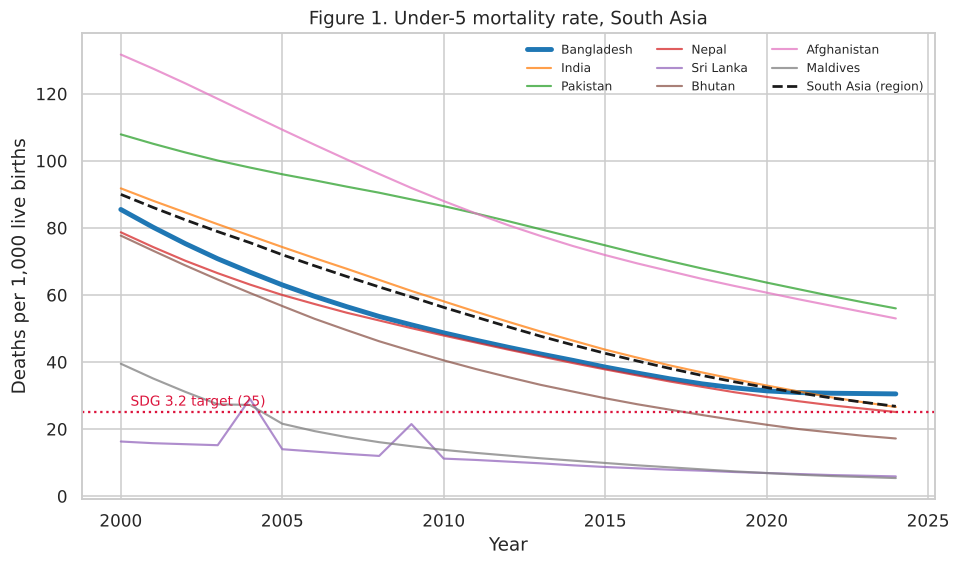

In [7]:
palette = dict(zip(COUNTRIES.values(), sns.color_palette("tab10", len(COUNTRIES))))
fig, ax = plt.subplots(figsize=(10, 5.5))
for iso, name in COUNTRIES.items():
    s = df[df["iso3"] == iso]
    ax.plot(s["year"], s["u5mr"], label=name, color=palette[name],
            lw=3.2 if iso == "BGD" else 1.4, alpha=1 if iso == "BGD" else 0.75)
sas = df[df["iso3"] == "SAS"]
ax.plot(sas["year"], sas["u5mr"], "k--", lw=1.8, label="South Asia (region)")
ax.axhline(SDG_U5MR, color="crimson", ls=":", lw=1.5)
ax.text(START + 0.3, SDG_U5MR + 2, f"SDG 3.2 target ({SDG_U5MR})", color="crimson", fontsize=9)
ax.set(title="Figure 1. Under-5 mortality rate, South Asia", xlabel="Year", ylabel="Deaths per 1,000 live births")
ax.legend(ncol=3, fontsize=8, frameon=False)
fig.savefig(FIG / "fig1_u5mr_south_asia.png"); plt.show()

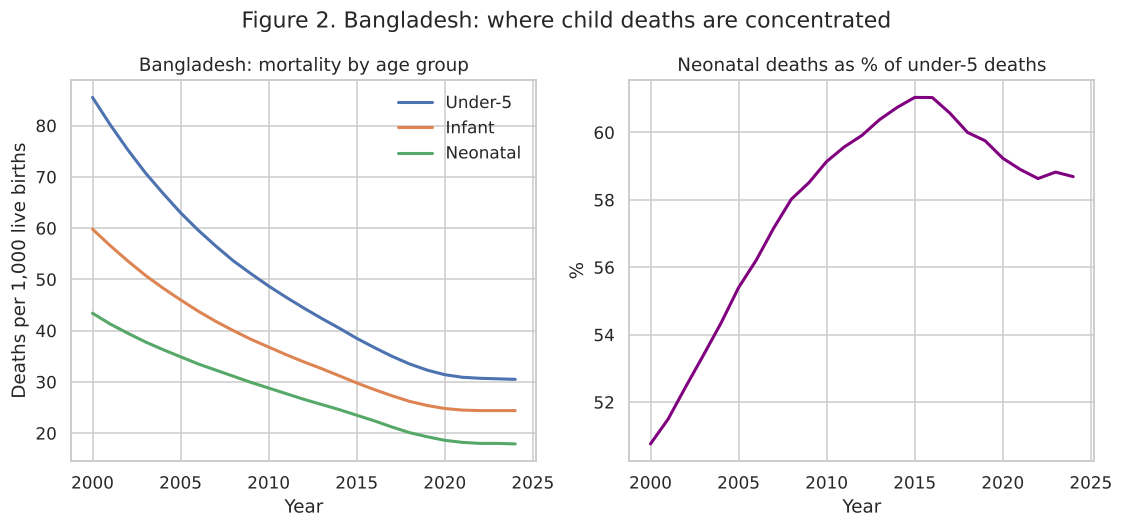

In [8]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.5))
for c, lab in [("u5mr", "Under-5"), ("imr", "Infant"), ("nmr", "Neonatal")]:
    a1.plot(bd.index, bd[c], lw=2, label=lab)
a1.set(title="Bangladesh: mortality by age group", xlabel="Year", ylabel="Deaths per 1,000 live births")
a1.legend(frameon=False)
a2.plot(bd.index, bd["neonatal_share"], color="purple", lw=2)
a2.set(title="Neonatal deaths as % of under-5 deaths", xlabel="Year", ylabel="%")
fig.suptitle("Figure 2. Bangladesh: where child deaths are concentrated", y=1.02)
fig.savefig(FIG / "fig2_bd_age_groups.png"); plt.show()

ns = bd["neonatal_share"].dropna()
results["neonatal_share_start"], results["neonatal_share_latest"] = round(ns.iloc[0], 1), round(ns.iloc[-1], 1)
results["neonatal_share_years"] = (int(ns.index[0]), int(ns.index[-1]))

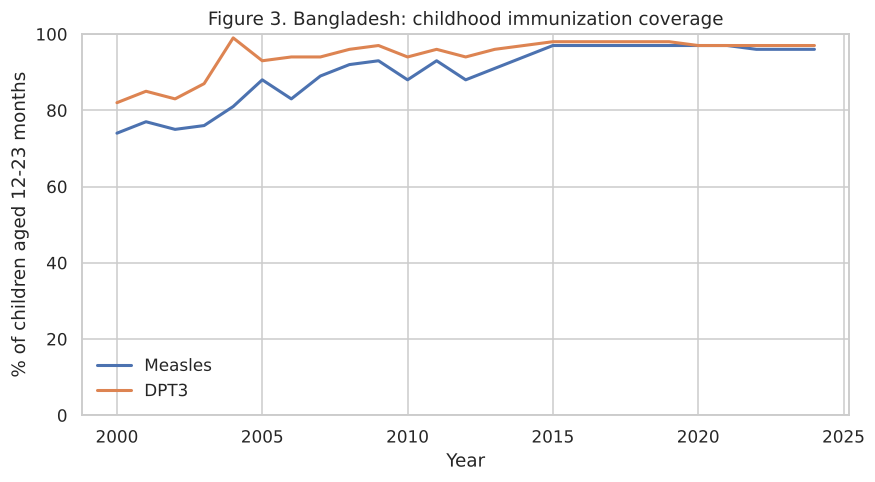

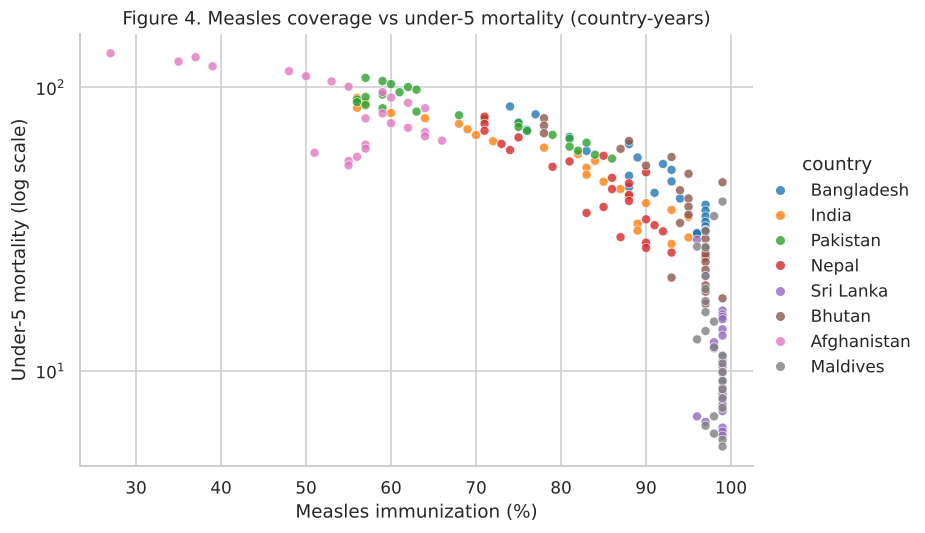

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(bd.index, bd["measles"], lw=2, label="Measles")
ax.plot(bd.index, bd["dpt3"], lw=2, label="DPT3")
ax.set(title="Figure 3. Bangladesh: childhood immunization coverage", xlabel="Year",
       ylabel="% of children aged 12-23 months", ylim=(0, 100))
ax.legend(frameon=False)
fig.savefig(FIG / "fig3_bd_immunization.png"); plt.show()

panel = df[df["iso3"].isin(COUNTRIES)].copy()
g = sns.relplot(data=panel, x="measles", y="u5mr", hue="country", palette=palette,
                height=4.8, aspect=1.5, s=35, alpha=0.8)
g.ax.set_yscale("log")
g.set(title="Figure 4. Measles coverage vs under-5 mortality (country-years)",
      xlabel="Measles immunization (%)", ylabel="Under-5 mortality (log scale)")
g.savefig(FIG / "fig4_measles_vs_u5mr.png"); plt.show()

## 4. Statistical analysis
### 4.1 Rate of decline in Bangladesh and test for a slowdown
Log-linear trend model, log(rate) = β₀ + β₁·t, so ARR ≈ −100·β₁.
A piecewise (segmented) term, (year − BREAK_YEAR)₊, tests whether the slope changed after the break year.
Annual series are autocorrelated, so standard errors are **Newey–West (HAC)**.

In [10]:
def trend_models(series_df, col):
    d = series_df.dropna(subset=[col]).reset_index().rename(columns={"index": "year"})
    d["t"] = d["year"] - START
    d["t_late"] = (d["year"] - BREAK_YEAR).clip(lower=0)
    d["y"] = np.log(d[col])
    lin = smf.ols("y ~ t", d).fit(cov_type="HAC", cov_kwds={"maxlags": 2})
    seg = smf.ols("y ~ t + t_late", d).fit(cov_type="HAC", cov_kwds={"maxlags": 2})
    return d, lin, seg

def arr_ci(model, contrast):
    tt = model.t_test(contrast)
    est, (lo, hi) = float(np.squeeze(tt.effect)), np.squeeze(tt.conf_int())
    return -100 * est, -100 * hi, -100 * lo, est, lo, hi

rows = []
for col, label in [("u5mr", "Under-5"), ("imr", "Infant"), ("nmr", "Neonatal")]:
    d, lin, seg = trend_models(bd, col)
    a, a_lo, a_hi, *_ = arr_ci(lin, "t = 0")
    e, e_lo, e_hi, *_ = arr_ci(seg, "t = 0")
    l, l_lo, l_hi, *_ = arr_ci(seg, "t + t_late = 0")
    rows.append({"Indicator": label,
                 "ARR whole period % (95% CI)": f"{a:.1f} ({a_lo:.1f} to {a_hi:.1f})",
                 f"ARR before {BREAK_YEAR} %": f"{e:.1f} ({e_lo:.1f} to {e_hi:.1f})",
                 f"ARR from {BREAK_YEAR} %": f"{l:.1f} ({l_lo:.1f} to {l_hi:.1f})",
                 "Slope change p-value": f"{seg.pvalues['t_late']:.3g}",
                 "Durbin-Watson": round(durbin_watson(lin.resid), 2)})
    results[f"{col}_arr"] = (round(a, 1), round(a_lo, 1), round(a_hi, 1))
    results[f"{col}_arr_early"], results[f"{col}_arr_late"] = round(e, 1), round(l, 1)
    results[f"{col}_slowdown_p"] = float(seg.pvalues["t_late"])
trend_table = pd.DataFrame(rows).set_index("Indicator")
print("Table 3. Bangladesh: annual rate of reduction (log-linear models, HAC standard errors)")
trend_table

Table 3. Bangladesh: annual rate of reduction (log-linear models, HAC standard errors)


,ARR whole period % (95% CI),ARR before 2012 %,ARR from 2012 %,Slope change p-value,Durbin-Watson
Indicator,,,,,
Under-5,4.5 (4.0 to 5.0),5.6 (5.3 to 6.0),3.4 (2.8 to 4.0),3.59e-07,0.13
Infant,4.0 (3.5 to 4.4),4.9 (4.6 to 5.3),3.0 (2.4 to 3.6),1.03e-05,0.15
Neonatal,3.9 (3.7 to 4.2),4.2 (3.9 to 4.4),3.7 (3.2 to 4.3),0.262,0.30


### 4.2 Is Bangladesh on track for SDG 3.2?
Project the latest value to 2030 using the **post-break** rate of decline (with its 95% CI), and compare with the ARR required to reach each target.

In [11]:
rows = []
for col, target, label in [("u5mr", SDG_U5MR, "Under-5"), ("nmr", SDG_NMR, "Neonatal")]:
    d, lin, seg = trend_models(bd, col)
    last_year, last_val = int(d["year"].iloc[-1]), float(d[col].iloc[-1])
    horizon = SDG_YEAR - last_year
    _, _, _, slope, lo, hi = arr_ci(seg, "t + t_late = 0")
    proj = last_val * np.exp(slope * horizon)
    proj_lo, proj_hi = last_val * np.exp(lo * horizon), last_val * np.exp(hi * horizon)
    required = 100 * np.log(last_val / target) / horizon if last_val > target else 0.0
    current = -100 * slope
    on_track = proj_hi <= target if last_val > target else True
    rows.append({"Indicator": label, f"Latest ({last_year})": round(last_val, 1), "SDG target": target,
                 f"Projected {SDG_YEAR} (95% CI)": f"{proj:.1f} ({proj_lo:.1f}-{proj_hi:.1f})",
                 "Current ARR %": round(current, 1), "Required ARR %": round(required, 1),
                 "Assessment": "On track" if on_track else ("Uncertain" if proj_lo <= target else "Off track")})
    results[f"{col}_sdg"] = rows[-1]
sdg_table = pd.DataFrame(rows).set_index("Indicator")
print("Table 4. SDG 3.2 projection for Bangladesh (assumes the post-break trend continues)")
sdg_table

Table 4. SDG 3.2 projection for Bangladesh (assumes the post-break trend continues)


,Latest (2024),SDG target,Projected 2030 (95% CI),Current ARR %,Required ARR %,Assessment
Indicator,,,,,,
Under-5,30.5,25,24.9 (24.0-25.8),3.4,3.3,Uncertain
Neonatal,17.9,12,14.3 (13.8-14.8),3.7,6.7,Off track


### 4.3 Determinants across South Asia: fixed-effects panel regression
Model: log(U5MR) = β₁·measles + β₂·log(GDP pc) + β₃·water + country fixed effects + linear year trend.

Country fixed effects remove stable differences between countries (health systems, geography, culture), so coefficients reflect **within-country** changes over time.
A pooled model without fixed effects is shown for comparison. Standard errors are clustered by country; with only 8 clusters, these p-values should be read cautiously.

In [12]:
model_vars = ["log_u5mr", "measles", "log_gdp", "water"]
pdat = panel.dropna(subset=model_vars).copy()
pdat["t"] = pdat["year"] - START          # centred time trend (numerically stable)
groups = pd.factorize(pdat["iso3"])[0]
cl = dict(cov_type="cluster", cov_kwds={"groups": groups}, use_t=True)

pooled = smf.ols("log_u5mr ~ measles + log_gdp + water + t", pdat).fit(**cl)
fe = smf.ols("log_u5mr ~ measles + log_gdp + water + t + C(iso3)", pdat).fit(**cl)

def tidy(m, name):
    ci = m.conf_int()
    keep = ["measles", "log_gdp", "water", "t"]
    return pd.DataFrame({"model": name, "coef": m.params[keep], "ci_low": ci.loc[keep, 0],
                         "ci_high": ci.loc[keep, 1], "p": m.pvalues[keep]})

coef_table = pd.concat([tidy(pooled, "Pooled OLS"), tidy(fe, "Country fixed effects")]).round(4)
print(f"Observations: {len(pdat)} country-years, {pdat['iso3'].nunique()} countries")
print(f"R² pooled = {pooled.rsquared:.3f}; R² fixed effects = {fe.rsquared:.3f}")
display(coef_table)

b, lo, hi = fe.params["measles"], *fe.conf_int().loc["measles"]
pct = lambda x: 100 * (np.exp(10 * x) - 1)
results["fe_measles"] = (round(pct(b), 1), round(pct(lo), 1), round(pct(hi), 1), float(fe.pvalues["measles"]))
results["fe_n"] = (len(pdat), pdat["iso3"].nunique())
print(f"\nInterpretation (fixed effects): a 10-point rise in measles coverage is associated with a "
      f"{pct(b):.1f}% change in under-5 mortality (95% CI {pct(lo):.1f}% to {pct(hi):.1f}%), "
      f"holding income, water access, the time trend and country constant.")

X = sm.add_constant(pdat[["measles", "log_gdp", "water", "t"]])
vif = pd.Series([variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])],
                index=X.columns[1:], name="VIF").round(1)
print("\nMulticollinearity check (VIF > 10 indicates strong collinearity):")
print(vif.to_string())

Observations: 200 country-years, 8 countries
R² pooled = 0.820; R² fixed effects = 0.978


,model,coef,ci_low,ci_high,p
measles,Pooled OLS,-0.0259,-0.0486,-0.0032,0.0306
log_gdp,Pooled OLS,-0.5180,-0.6663,-0.3698,0.0001
water,Pooled OLS,0.0189,-0.0032,0.0411,0.0830
t,Pooled OLS,-0.0242,-0.0528,0.0044,0.0858
measles,Country fixed effects,0.0073,-0.0051,0.0197,0.2052
log_gdp,Country fixed effects,-0.1962,-0.8564,0.4641,0.5050
water,Country fixed effects,0.0022,-0.0140,0.0184,0.7552
t,Country fixed effects,-0.0516,-0.0924,-0.0107,0.0203



Interpretation (fixed effects): a 10-point rise in measles coverage is associated with a 7.6% change in under-5 mortality (95% CI -4.9% to 21.7%), holding income, water access, the time trend and country constant.

Multicollinearity check (VIF > 10 indicates strong collinearity):
measles    3.3
log_gdp    2.4
water      2.4
t          1.2


## 5. Machine learning comparison
Can country-level indicators predict under-5 mortality in a country the model has **never seen**?
**Leave-one-country-out** cross-validation: train on 7 countries, predict the 8th, repeat. Error is RMSE on the log scale (≈ relative error).

Table 5. Leave-one-country-out prediction of log under-5 mortality


,RMSE (log scale),Approx. median relative error %
Model,,
Linear regression,0.627,34.773
Random forest,0.550,23.841



RMSE by held-out country:


,Linear regression,Random forest
Afghanistan,1.267,0.271
Bangladesh,0.244,0.283
Bhutan,0.415,0.643
India,0.306,0.087
Maldives,0.437,0.498
Nepal,0.286,0.286
Pakistan,0.471,0.306
Sri Lanka,0.847,1.191


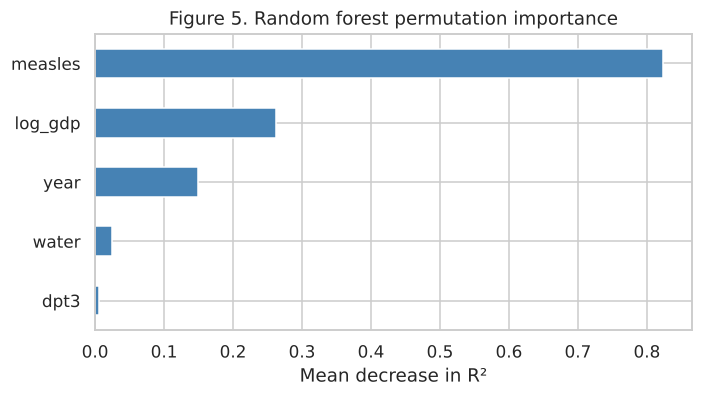

In [13]:
features = ["measles", "dpt3", "log_gdp", "water", "year"]
mdat = panel.dropna(subset=features + ["log_u5mr"]).copy()
X, y, grp = mdat[features].values, mdat["log_u5mr"].values, mdat["iso3"].values
logo = LeaveOneGroupOut()
models = {"Linear regression": LinearRegression(),
          "Random forest": RandomForestRegressor(n_estimators=500, min_samples_leaf=3, random_state=SEED, n_jobs=-1)}

rows, per_country = [], {}
for name, mdl in models.items():
    pred = cross_val_predict(mdl, X, y, groups=grp, cv=logo)
    err = pd.Series((pred - y) ** 2, index=mdat["country"].values)
    per_country[name] = np.sqrt(err.groupby(level=0).mean())
    rows.append({"Model": name, "RMSE (log scale)": np.sqrt(err.mean()),
                 "Approx. median relative error %": 100 * np.median(np.abs(np.exp(pred - y) - 1))})
ml_table = pd.DataFrame(rows).set_index("Model").round(3)
results["ml"] = ml_table.to_dict(orient="index")
print("Table 5. Leave-one-country-out prediction of log under-5 mortality")
display(ml_table)
print("\nRMSE by held-out country:")
display(pd.DataFrame(per_country).round(3))

rf = models["Random forest"].fit(X, y)
imp = permutation_importance(rf, X, y, n_repeats=20, random_state=SEED)
imp_s = pd.Series(imp.importances_mean, index=features).sort_values()
ax = imp_s.plot.barh(figsize=(7, 3.5), color="steelblue")
ax.set(title="Figure 5. Random forest permutation importance", xlabel="Mean decrease in R²")
plt.savefig(FIG / "fig5_rf_importance.png"); plt.show()

## 6. Summary of findings

In [14]:
import json
R = results
u, n = R["u5mr_sdg"], R["nmr_sdg"]
lr, rf = R["ml"]["Linear regression"]["RMSE (log scale)"], R["ml"]["Random forest"]["RMSE (log scale)"]
summary = [
    f"Bangladesh's under-5 mortality fell at an average {R['u5mr_arr'][0]}% per year ({START}-{R['latest_year']}; 95% CI {R['u5mr_arr'][1]} to {R['u5mr_arr'][2]}).",
    f"The rate of decline was {R['u5mr_arr_early']}% per year before {BREAK_YEAR} and {R['u5mr_arr_late']}% per year after (test for slope change p = {R['u5mr_slowdown_p']:.3g}).",
    f"Neonatal deaths rose from {R['neonatal_share_start']}% to {R['neonatal_share_latest']}% of all under-5 deaths ({R['neonatal_share_years'][0]}-{R['neonatal_share_years'][1]}); neonatal mortality declined at {R['nmr_arr'][0]}% per year versus {R['u5mr_arr'][0]}% for under-5.",
    f"SDG 3.2 (under-5 ≤ {SDG_U5MR}): projected {SDG_YEAR} value {u[f'Projected {SDG_YEAR} (95% CI)']}; current ARR {u['Current ARR %']}% vs required {u['Required ARR %']}% -> {u['Assessment']}.",
    f"SDG 3.2 (neonatal ≤ {SDG_NMR}): projected {SDG_YEAR} value {n[f'Projected {SDG_YEAR} (95% CI)']}; current ARR {n['Current ARR %']}% vs required {n['Required ARR %']}% -> {n['Assessment']}.",
    f"Across {R['fe_n'][1]} South Asian countries ({R['fe_n'][0]} country-years), a 10-point rise in measles coverage was associated with a {R['fe_measles'][0]}% change in under-5 mortality (95% CI {R['fe_measles'][1]}% to {R['fe_measles'][2]}%, p = {R['fe_measles'][3]:.3g}) after country fixed effects.",
    f"In leave-one-country-out validation, the {'random forest' if rf < lr else 'linear model'} predicted better (log-RMSE {min(rf, lr):.3f} vs {max(rf, lr):.3f}).",
]
for i, s in enumerate(summary, 1):
    print(f"{i}. {s}")
(RES / "summary.txt").write_text("\n".join(summary))
(RES / "results.json").write_text(json.dumps(R, indent=2, default=str))

1. Bangladesh's under-5 mortality fell at an average 4.5% per year (2000-2024; 95% CI 4.0 to 5.0).
2. The rate of decline was 5.6% per year before 2012 and 3.4% per year after (test for slope change p = 3.59e-07).
3. Neonatal deaths rose from 50.8% to 58.7% of all under-5 deaths (2000-2024); neonatal mortality declined at 3.9% per year versus 4.5% for under-5.
4. SDG 3.2 (under-5 ≤ 25): projected 2030 value 24.9 (24.0-25.8); current ARR 3.4% vs required 3.3% -> Uncertain.
5. SDG 3.2 (neonatal ≤ 12): projected 2030 value 14.3 (13.8-14.8); current ARR 3.7% vs required 6.7% -> Off track.
6. Across 8 South Asian countries (200 country-years), a 10-point rise in measles coverage was associated with a 7.6% change in under-5 mortality (95% CI -4.9% to 21.7%, p = 0.205) after country fixed effects.
7. In leave-one-country-out validation, the random forest predicted better (log-RMSE 0.550 vs 0.627).


1382

## 7. Limitations
- **Modelled estimates:** UN IGME mortality figures are smoothed model outputs, not direct observations. Trend models fitted to them will look very precise; confidence intervals understate true uncertainty.
- **Ecological design:** associations are at country level and cannot be interpreted as effects on individual children (ecological fallacy). Associations are not causal.
- **Few clusters:** only 8 countries, so cluster-robust p-values are approximate.
- **Collinearity:** income, water access and time trend upward together; VIFs were checked (all below 4), but separate effects remain hard to disentangle with 8 countries.
- **Break year** for the slowdown test was fixed a priori; other choices may change the result.
- **Interpolation:** a small number of interior gaps in coverage and GDP were linearly interpolated (flagged).
- **Projection** assumes the recent trend continues unchanged to 2030.

**Possible extensions:** sub-national analysis with Bangladesh DHS/MICS microdata (e.g., logistic regression of child survival on maternal education, birth spacing and facility delivery); joinpoint regression to estimate the break year from data.

## 8. Export outputs
All data, figures and results are bundled into one zip for download.

In [15]:
import zipfile
zip_path = BASE / "child_mortality_outputs.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for folder in ["data", "figures", "results"]:
        for f in sorted((BASE / folder).rglob("*")):
            if f.is_file():
                zf.write(f, f.relative_to(BASE))
print(f"Saved {zip_path} ({zip_path.stat().st_size / 1024:.0f} KB)")
print("Contents:", *zipfile.ZipFile(zip_path).namelist(), sep="\n  ")

Saved child_mortality_outputs.zip (506 KB)
Contents:
  data/clean_panel.csv
  data/raw/worldbank_indicators.csv
  figures/fig1_u5mr_south_asia.png
  figures/fig2_bd_age_groups.png
  figures/fig3_bd_immunization.png
  figures/fig4_measles_vs_u5mr.png
  figures/fig5_rf_importance.png
  results/results.json
  results/summary.txt
